
# SWYNEX Internship — Task 3
## Model Improvement and Validation

**Objective:** Improve and validate a machine learning classification model through hyperparameter tuning and cross-validation.

**Dataset:** Breast Cancer Wisconsin Diagnostic Dataset

**Baseline model:** Logistic Regression

**Improvement technique:** StandardScaler pipeline and GridSearchCV with stratified 5-fold cross-validation.


In [1]:

# Task 3: Model Improvement
# SWYNEX Machine Learning Internship

# Import libraries for data handling and evaluation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import the dataset
from sklearn.datasets import load_breast_cancer

# Import tools for splitting and evaluation
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Import model and preprocessing tools
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Load the Breast Cancer Wisconsin dataset
dataset = load_breast_cancer()

# Convert features into a DataFrame
X = pd.DataFrame(dataset.data, columns=dataset.feature_names)

# Convert target labels into a Series
y = pd.Series(dataset.target, name="target")

# Display basic dataset information
print("Dataset shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts().rename(index={0: "Malignant", 1: "Benign"}))

print("\nFirst five rows:")
display(X.head())


Dataset shape: (569, 30)

Target distribution:
target
Benign       357
Malignant    212
Name: count, dtype: int64

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [2]:

# Step 2: Create a consistent train/test split

# Keep 20% of the data for final testing.
# Stratification preserves the proportion of benign and malignant cases.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

# Create the baseline Logistic Regression pipeline.
# Scaling is fitted only on the training data.
baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000))
])

# Train the baseline model
baseline_model.fit(X_train, y_train)

# Predict class labels and probabilities on the test set
y_pred_baseline = baseline_model.predict(X_test)
y_prob_baseline = baseline_model.predict_proba(X_test)[:, 1]

# Calculate baseline evaluation metrics
baseline_results = {
    "Model": "Baseline Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred_baseline),
    "Precision": precision_score(y_test, y_pred_baseline),
    "Recall": recall_score(y_test, y_pred_baseline),
    "F1-Score": f1_score(y_test, y_pred_baseline),
    "ROC-AUC": roc_auc_score(y_test, y_prob_baseline)
}

print("\nBaseline results:")
print(pd.DataFrame([baseline_results]).round(4).to_string(index=False))


Training samples: 455
Testing samples: 114

Baseline results:
                       Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Baseline Logistic Regression    0.9825     0.9861  0.9861    0.9861   0.9954


In [3]:

# Step 3: Hyperparameter tuning with GridSearchCV

# Create a pipeline so scaling is performed correctly
# within each cross-validation fold.
tuning_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000))
])

# Define the hyperparameter combinations to evaluate
param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["lbfgs"],
    "model__class_weight": [None, "balanced"]
}

# Use stratified 5-fold cross-validation
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Search for the best hyperparameters using F1-score
grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    refit=True
)

# Train and evaluate candidate configurations on training data only
grid_search.fit(X_train, y_train)

# Display the best configuration and cross-validation score
print("Best hyperparameters:")
print(grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(grid_search.best_score_, 4))

# Save the best estimator
tuned_model = grid_search.best_estimator_


Best hyperparameters:
{'model__C': 0.1, 'model__class_weight': None, 'model__solver': 'lbfgs'}

Best cross-validation F1-score:
0.9861


In [4]:

# Step 4: Evaluate the tuned model on the test set

# Generate predictions using the best model
y_pred_tuned = tuned_model.predict(X_test)
y_prob_tuned = tuned_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
tuned_results = {
    "Model": "Tuned Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred_tuned),
    "Precision": precision_score(y_test, y_pred_tuned),
    "Recall": recall_score(y_test, y_pred_tuned),
    "F1-Score": f1_score(y_test, y_pred_tuned),
    "ROC-AUC": roc_auc_score(y_test, y_prob_tuned)
}

# Display the results
print("Tuned Model Results:")
print(pd.DataFrame([tuned_results]).round(4).to_string(index=False))

# Display the classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=dataset.target_names
))


Tuned Model Results:
                    Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Tuned Logistic Regression    0.9737     0.9726  0.9861    0.9793   0.9957

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.95      0.96        42
      benign       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



Baseline vs Tuned Model


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Baseline Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9954
1,Tuned Logistic Regression,0.9737,0.9726,0.9861,0.9793,0.9957


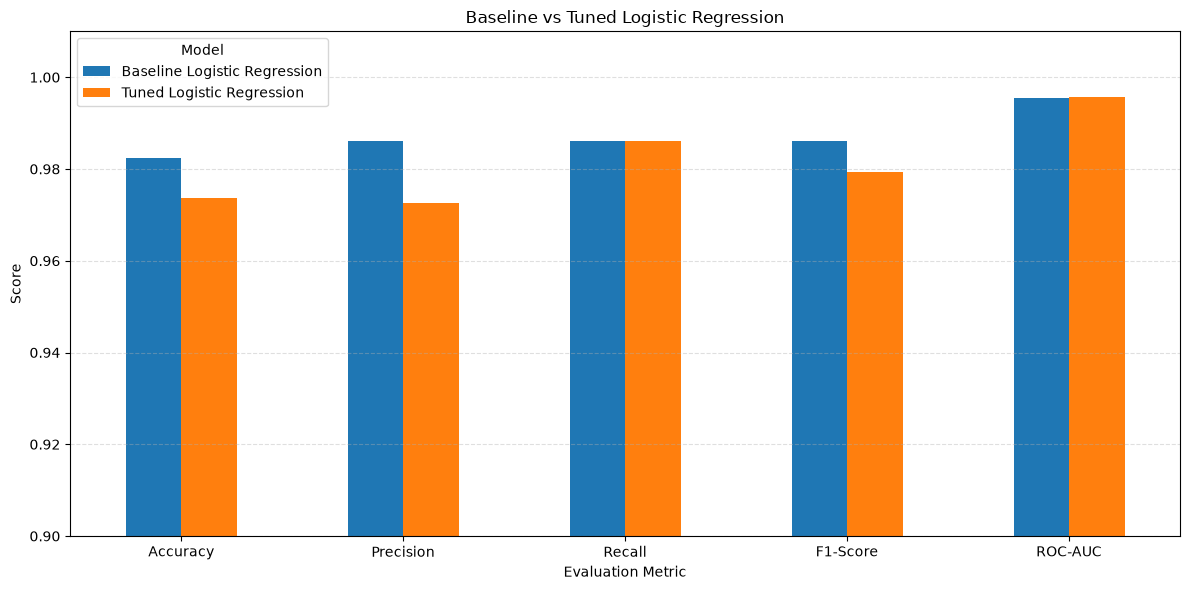

In [5]:

# Step 5: Compare baseline and tuned models

comparison_df = pd.DataFrame([
    baseline_results,
    tuned_results
])

print("Baseline vs Tuned Model")
display(comparison_df.round(4))

# Plot a comparison of all evaluation metrics
metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

comparison_df.set_index("Model")[metrics].T.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0.90, 1.01),
    rot=0
)

plt.title("Baseline vs Tuned Logistic Regression")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.legend(title="Model")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


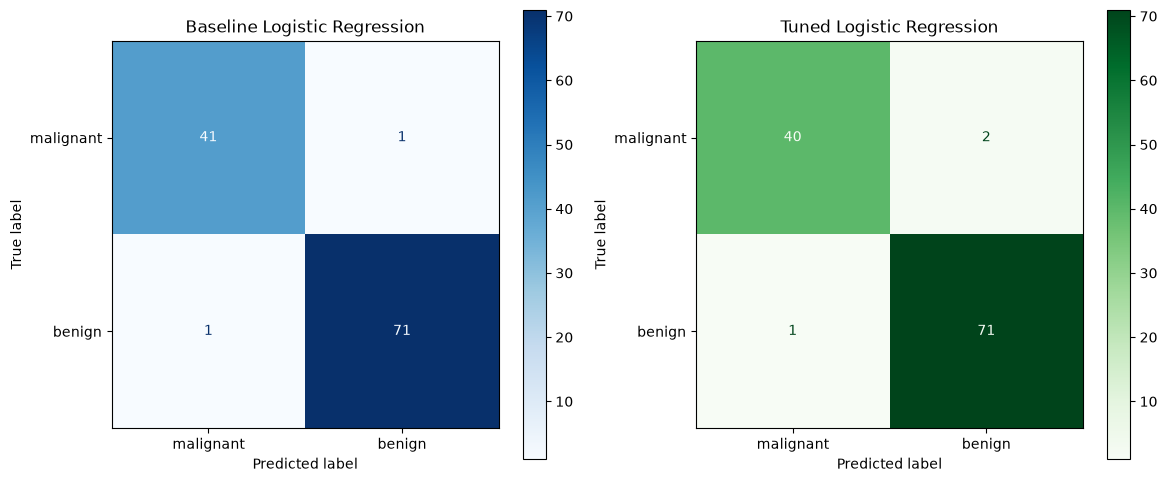

In [7]:

# Step 6: Compare confusion matrices

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay = __import__(
    "sklearn.metrics", fromlist=["ConfusionMatrixDisplay"]
).ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_baseline,
    display_labels=dataset.target_names,
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Baseline Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned,
    display_labels=dataset.target_names,
    cmap="Greens",
    ax=axes[1]
)
axes[1].set_title("Tuned Logistic Regression")

plt.tight_layout()
plt.show()


In [8]:

# Step 7: Save model comparison results

comparison_df.to_csv("model_improvement_results.csv", index=False)

print("Results saved to model_improvement_results.csv")
print("\nFinal comparison:")
display(comparison_df.round(4))


Results saved to model_improvement_results.csv

Final comparison:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Baseline Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9954
1,Tuned Logistic Regression,0.9737,0.9726,0.9861,0.9793,0.9957
